# 09 — Credit portfolio optimisation

**Goal:** an investor buys LendingClub notes at par and holds them to the end. How should the money be
spread across loan segments, and does an optimiser beat simply buying everything?

- **Segments:** our rating grade × LendingClub grade (E, F, G merged). An investor sees both when a
  loan is issued.
- **Expected return** per dollar over the loan's life:
  E[R] = (1 − PD) × cash if repaid + PD × cash if defaulted − 1, after a 1% servicing fee.
- **Tail risk:** 99% CVaR of lifetime return across economies from the one-factor model (notebook 07),
  minimised or limited with the Rockafellar–Uryasev linear programme.
- **Backtest:** every choice uses only information available at origination, then is scored on what
  the 2015 loans actually returned.

In [1]:
import os, sys, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pdmodel import config as C
pd.set_option("display.float_format", "{:.4f}".format)
PROC = ROOT / "data" / "processed"
from pdmodel import optimisation as O, plots, portfolio as P, simulation as MC

In [2]:
S = pd.read_pickle(PROC / "samples.pkl")
cm = pd.read_pickle(PROC / "validation.pkl")["calibrated_model"]
oot = S["oot"]
hist = pd.concat([S["train"], S["test"], S["calib"]], ignore_index=True)   # loans issued 2007-14
port = P.build_portfolio(oot, cm.predict_pd(oot), cm.grade(oot), P.estimate_loss_parameters(hist, cm.grade(hist)))
rho = MC.basel_retail_correlation(MC.annualised_pd(port["pd"].to_numpy(), C.TERM_YEARS))

## 1. Cash flows per dollar

`total_pymnt` is exactly principal + interest + late fees + recoveries, so what each loan paid is
known exactly. To turn a loan's rate into expected interest, measure how much interest earlier loans
actually earned per unit of rate: repaid loans earn less than the full schedule because many are repaid
early, and defaulted loans stop paying part-way.

In [3]:
carry = O.carry_factors(hist)
carry

,loans,k_good,k_bad
lc_band,,,
A,72888.0000,1.3307,1.1005
B,120242.0000,1.3406,1.0867
C,84979.0000,1.3299,1.0519
D,43952.0000,1.3361,1.0093
E–G,15935.0000,1.3375,0.9535


## 2. Segments: expected and realised returns

In [4]:
seg, lab, terms = O.segment_inputs(port, oot, carry, C.SERVICING_FEE, C.OPT_MIN_LOANS, C.CHARGEOFF_LAG_MONTHS)
print(f"{len(seg)} segments covering {seg['exposure'].sum() / port['exposure'].sum():.1%} of the 2015 book")
seg[["loans", "mean_pd", "mean_rate", "expected_return", "el_rate", "observed_dr", "realised_return", "realised_annualised"]]

32 segments covering 99.6% of the 2015 book


,loans,mean_pd,mean_rate,expected_return,el_rate,observed_dr,realised_return,realised_annualised
seg,,,,,,,,
1 / A,28038,0.0468,6.5177,0.0539,0.0222,0.0347,0.0595,0.0450
1 / B,7948,0.0532,9.6175,0.0913,0.0251,0.0761,0.0696,0.0553
1 / C,2199,0.0541,13.0414,0.1352,0.0255,0.1310,0.0628,0.0525
2 / A,17682,0.0769,6.9920,0.0445,0.0370,0.0568,0.0591,0.0435
2 / B,15773,0.0784,9.7696,0.0803,0.0377,0.0957,0.0679,0.0519
2 / C,6176,0.0791,13.0823,0.1222,0.0380,0.1535,0.0667,0.0529
2 / D,1359,0.0795,16.5096,0.1668,0.0382,0.1994,0.0570,0.0468
3 / A,11047,0.0994,7.1818,0.0346,0.0489,0.0640,0.0555,0.0405
3 / B,17863,0.1003,9.9125,0.0702,0.0493,0.1105,0.0655,0.0493


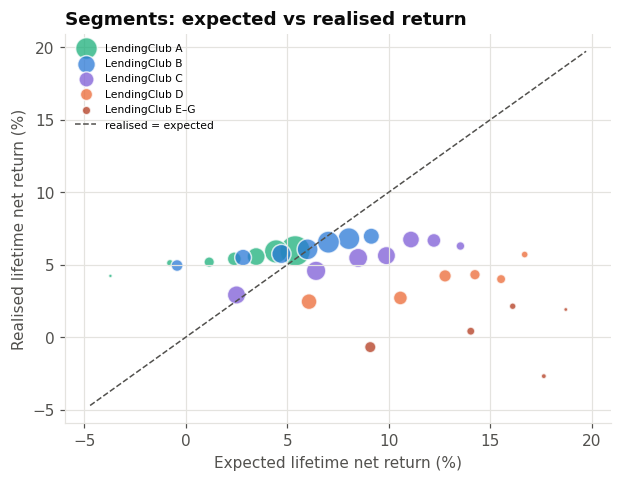

In [5]:
plots.segment_scatter(seg); plt.show()

## 3. Economies and the strategies

Segment returns in 10,000 sampled economies. With one economy factor and thousands of loans per segment,
every segment loses in the same bad economies, so spreading across segments does not cut tail risk the
way it would with several factors; the limits decide how concentrated a portfolio can be.

In [6]:
R = O.scenario_returns(port, terms, lab, seg.index, rho, C.OPT_SCENARIOS, C.OPT_SEED)
mu, el = seg["expected_return"].to_numpy(), seg["el_rate"].to_numpy()
cons = O.Constraints(w_max=C.OPT_MAX_WEIGHT, groups=O.group_caps(seg, "lc_band", C.OPT_BAND_CAP))
pd.Series(O.STRATEGIES, name="what it does").to_frame()

,what it does
Whole book,"every loan, in proportion to its size (benchmark)"
Equal weight,the same amount in every segment
Max expected return,highest expected return within the limits
Min expected loss,lowest expected loss within the limits
Min CVaR,lowest 99% CVaR within the limits
"Max return, CVaR ≤ book",highest expected return with 99% CVaR no worse...
"Max return, EL ≤ book",highest expected return with expected loss no ...


In [7]:
W = O.run_strategies(mu, el, R, seg, cons, C.OPT_ALPHA)
table = O.strategy_table(W, mu, el, R, seg, C.OPT_ALPHA)
table[["expected_return", "el_rate", "cvar_0.99", "realised_return", "realised_annualised", "realised_loss_rate", "segments_held"]]

,expected_return,el_rate,cvar_0.99,realised_return,realised_annualised,realised_loss_rate,segments_held
strategy,,,,,,,
Whole book,0.0686,0.0637,0.0224,0.0530,0.0403,0.0754,32.0000
Equal weight,0.0829,0.0719,0.0120,0.0445,0.0343,0.1012,32.0000
Max expected return,0.1491,0.0535,-0.0546,0.0374,0.0307,0.1408,11.0000
Min expected loss,0.0910,0.0371,-0.0067,0.0631,0.0489,0.0574,10.0000
Min CVaR,0.1491,0.0535,-0.0546,0.0374,0.0307,0.1408,11.0000
"Max return, CVaR ≤ book",0.1491,0.0535,-0.0546,0.0374,0.0307,0.1408,11.0000
"Max return, EL ≤ book",0.1491,0.0535,-0.0546,0.0374,0.0307,0.1408,11.0000


best possible within the same limits, with hindsight: 6.34%


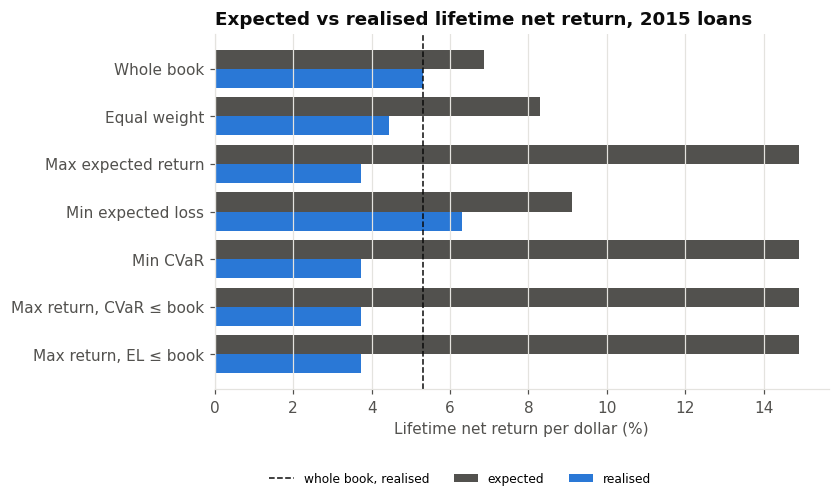

In [8]:
hindsight = O.optimise(seg["realised_return"].to_numpy(), el, R, "max_return", cons, C.OPT_ALPHA)
print(f"best possible within the same limits, with hindsight: {hindsight @ seg['realised_return']:.2%}")
plots.strategy_outcomes_plot(table); plt.show()

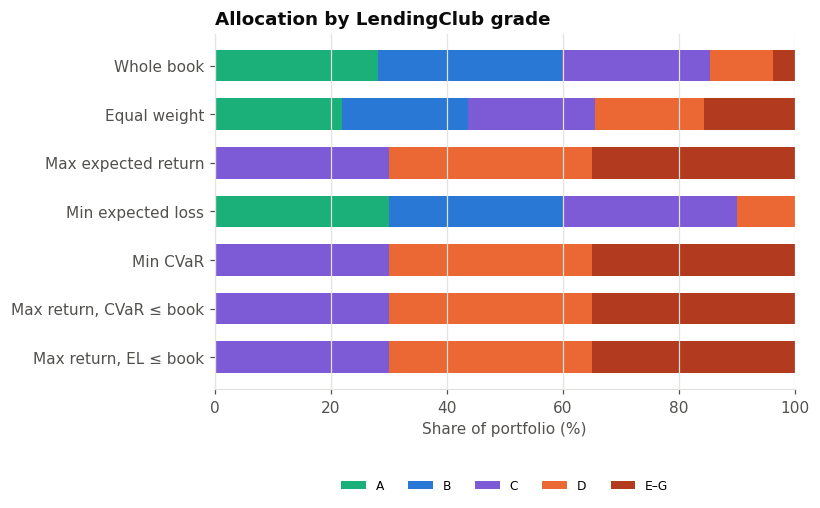

,Whole book,Equal weight,Max expected return,Min expected loss,Min CVaR,"Max return, CVaR ≤ book","Max return, EL ≤ book"
seg,,,,,,,
1 / A,0.1200,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000
1 / B,0.0340,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000
1 / C,0.0100,0.0310,0.1000,0.1000,0.1000,0.1000,0.1000
2 / A,0.0710,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000
2 / B,0.0620,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000
2 / C,0.0250,0.0310,0.1000,0.1000,0.1000,0.1000,0.1000
2 / D,0.0060,0.0310,0.1000,0.1000,0.1000,0.1000,0.1000
3 / A,0.0420,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000
3 / B,0.0630,0.0310,0.0000,0.1000,0.0000,0.0000,0.0000


In [9]:
weights = pd.DataFrame(W, index=seg.index)
plots.allocation_plot(weights.groupby(seg["lc_band"]).sum().T); plt.show()
weights[weights.drop(columns=["Whole book", "Equal weight"]).max(axis=1) > 1e-4].round(3)

Each segment's expected return against its own tail risk. Under the scorecard model the high-rate segments
look both the most profitable and the safest, so the frontier collapses to one portfolio.

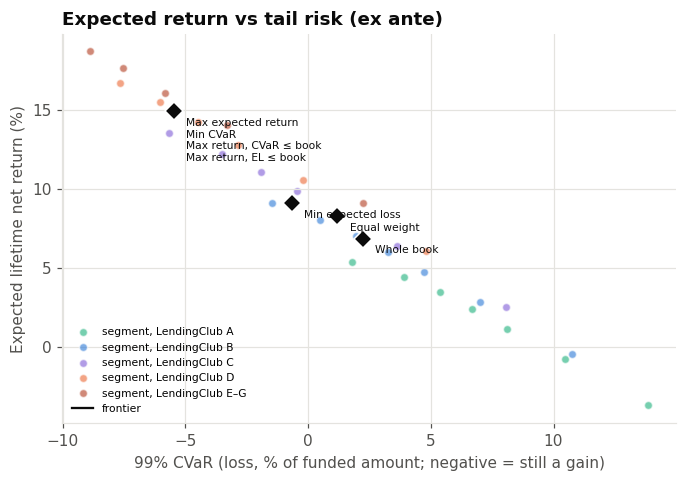

In [10]:
seg["cvar_0.99"] = [O.cvar(R[:, k], C.OPT_ALPHA) for k in range(len(seg))]
front = O.frontier(mu, el, R, cons, C.OPT_ALPHA, C.OPT_FRONTIER_POINTS)
plots.frontier_plot(front, table, seg); plt.show()

## 4. Why reaching for return failed

Break the gap between expected and realised return down by LendingClub grade band: the default rate,
the interest earned by repaid loans, and the cash recovered from defaults.

In [11]:
O.gap_by_band(port, oot, carry, C.SERVICING_FEE)

,loans,mean_rate,mean_pd,observed_dr,k_good_assumed,k_good_realised,default_cash_assumed,default_cash_realised,expected_return,expected_return_at_actual_dr,realised_return
lc_band,,,,,,,,,,,
A,70118.0000,0.0690,0.0807,0.0542,1.3307,1.3310,0.5844,0.6238,0.0418,0.0541,0.0576
B,91725.0000,0.1002,0.1237,0.1190,1.3406,1.3167,0.6023,0.6232,0.0601,0.0608,0.0622
C,77423.0000,0.1324,0.1560,0.1944,1.3299,1.2950,0.6195,0.6084,0.0825,0.0591,0.0522
D,32711.0000,0.1664,0.1811,0.2622,1.3361,1.2741,0.6406,0.5882,0.1112,0.0615,0.0347
E–G,11049.0000,0.1983,0.2076,0.3431,1.3375,1.2663,0.6540,0.5710,0.1307,0.0457,0.0008


## 5. Other sources of expected return

Is the result specific to the scorecard? Re-run the strategies with two other inputs:

- **price-informed model:** each segment's PD scaled by its actual-to-predicted default ratio on 2007–14
  loans, which brings in LendingClub's grade;
- **segment history:** each segment's realised return on 2007–14 loans.

In [12]:
hist_cells = O.segment_labels(cm.grade(hist), hist["grade"])
port_pi = port.copy()
port_pi["pd"] = O.price_informed_pd(port["pd"], O.segment_labels(port["grade"], oot["grade"]), hist_cells,
                                    hist["default"], cm.predict_pd(hist))
seg_pi, lab_pi, terms_pi = O.segment_inputs(port_pi, oot, carry, C.SERVICING_FEE, C.OPT_MIN_LOANS, C.CHARGEOFF_LAG_MONTHS)
seg_pi = seg_pi.reindex(seg.index)
rho_pi = MC.basel_retail_correlation(MC.annualised_pd(port_pi["pd"].to_numpy(), C.TERM_YEARS))
R_pi = O.scenario_returns(port_pi, terms_pi, lab_pi, seg.index, rho_pi, C.OPT_SCENARIOS, C.OPT_SEED)
mu_h = O.historical_segment_returns(hist, hist_cells, seg.index, C.SERVICING_FEE).to_numpy()
inputs = {"Scorecard model": (mu, el, R),
          "Price-informed model": (seg_pi["expected_return"].to_numpy(), seg_pi["el_rate"].to_numpy(), R_pi),
          "Segment history": (mu_h, el, R - mu + mu_h)}
sens = pd.concat({name: O.strategy_table(O.run_strategies(m, e, r, seg, cons, C.OPT_ALPHA), m, e, r, seg, C.OPT_ALPHA)
                  [["expected_return", "realised_return"]] for name, (m, e, r) in inputs.items()}, axis=1)
sens

Scorecard model                 Price-informed model  \
                        expected_return realised_return      expected_return   
strategy                                                                       
Whole book                       0.0686          0.0530               0.0702   
Equal weight                     0.0829          0.0445               0.0786   
Max expected return              0.1491          0.0374               0.1194   
Min expected loss                0.0910          0.0631               0.0780   
Min CVaR                         0.1491          0.0374               0.1185   
Max return, CVaR ≤ book          0.1491          0.0374               0.1194   
Max return, EL ≤ book            0.1491          0.0374               0.1114   

                                        Segment history                  
                        realised_return expected_return realised_return  
strategy                                                                 
Whole book                       0.0530          0.0845          0.0530  
Equal weight                     0.0445          0.0883          0.0445  
Max expected return              0.0374          0.1174          0.0448  
Min expected loss                0.0631          0.0986          0.0631  
Min CVaR                         0.0406          0.1168          0.0508  
Max return, CVaR ≤ book          0.0374          0.1174          0.0448  
Max return, EL ≤ book            0.0480          0.1174          0.0448

In [13]:
pd.DataFrame({"scorecard_model": mu, "price_informed": seg_pi["expected_return"], "segment_history": mu_h,
              "realised_2015": seg["realised_return"]}, index=seg.index).corr()["realised_2015"].drop("realised_2015")

scorecard_model   -0.3535
price_informed    -0.2636
segment_history   -0.0138
Name: realised_2015, dtype: float64

## Findings
- Buying the whole 2015 book returned 5.30% net over the loans' life (about 4.0% a year), against 6.86%
  expected.
- **Minimising expected loss did best: 6.31%**, a point above the book and within 0.03 points of the best
  result possible with hindsight under the same limits (6.34%).
- **Every strategy that reached for expected return did worse than the book.** Maximising expected return
  forecast 14.91% and earned 3.74%. Under the scorecard model, minimising CVaR and the CVaR- and
  expected-loss-limited strategies pick the same portfolio: the model sees the high-rate segments as both
  the most profitable and the safest, so there is no trade-off for the limits to act on.
- Three errors pile up in the high-rate bands: the scorecard's PD barely rises with LendingClub's grade
  (20.8% predicted vs 34.3% actual for E–G), high-rate borrowers repaid early more often, and their
  defaults came earlier. For E–G loans the expected 13.1% became 0.1%.
- Neither a price-informed PD nor each segment's own history rescues the return seekers (best: 4.80% and
  5.08%). The lesson is about optimisation itself: it concentrates money where the inputs are most wrong.